# 🚗 자동차 데이터로 연비 예측하기
1970~1982년에 나온 자동차 398대의 실제 자료예요. 실린더 수, 배기량, 무게 등을 보고 **연비(mpg)를 숫자로 예측하는 회귀 모델**을 만들어 봐요.

| 열 이름 | 뜻 |
|---|---|
| mpg | 연비: 1갤런으로 가는 마일 수 (맞힐 값). 1 mpg ≈ 0.425 km/L |
| cylinders | 실린더 수 |
| displacement | 배기량 (세제곱인치) |
| horsepower | 마력 |
| weight | 무게 (파운드) |
| acceleration | 0→60마일 가속 시간 (초) |
| model_year | 출시 연도 (70 = 1970년) |
| origin | 생산지 (usa, europe, japan) |
| name | 차 이름 |

출처: UCI 머신러닝 저장소 Auto MPG, seaborn 예제 데이터. 웹 실습에서는 이 데이터를 km/L, kg 단위로 바꿔서 썼어요.

**Colab에서 할 때만** 아래 셀을 먼저 실행해 데이터 파일을 내려받아요. (웹 실습 페이지에서는 파일이 이미 준비되어 있어서 건너뛰어요.)

In [ ]:
!wget -q -O mpg.csv https://kang-teacher.github.io/AI/data/mpg.csv

## 1. 데이터 불러오기

In [1]:
import pandas as pd

df = pd.read_csv('mpg.csv')
df

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18,8,307,130,3504,12,70,usa,chevrolet chevelle malibu
1,15,8,350,165,3693,11.5,70,usa,buick skylark 320
2,18,8,318,150,3436,11,70,usa,plymouth satellite
3,16,8,304,150,3433,12,70,usa,amc rebel sst
4,17,8,302,140,3449,10.5,70,usa,ford torino
5,15,8,429,198,4341,10,70,usa,ford galaxie 500
...,...,...,...,...,...,...,...,...,...
392,27,4,151,90,2950,17.3,82,usa,chevrolet camaro
393,27,4,140,86,2790,15.6,82,usa,ford mustang gl
394,44,4,97,52,2130,24.6,82,europe,vw pickup


In [2]:
df.head(10)

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18,8,307,130,3504,12,70,usa,chevrolet chevelle malibu
1,15,8,350,165,3693,11.5,70,usa,buick skylark 320
2,18,8,318,150,3436,11,70,usa,plymouth satellite
3,16,8,304,150,3433,12,70,usa,amc rebel sst
4,17,8,302,140,3449,10.5,70,usa,ford torino
5,15,8,429,198,4341,10,70,usa,ford galaxie 500
6,14,8,454,220,4354,9,70,usa,chevrolet impala
7,14,8,440,215,4312,8.5,70,usa,plymouth fury iii
8,14,8,455,225,4425,10,70,usa,pontiac catalina
9,15,8,390,190,3850,8.5,70,usa,amc ambassador dpl


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    str    
 8   name          398 non-null    str    
dtypes: float64(4), int64(3), str(2)
memory usage: 28.1 KB


In [4]:
df.describe()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year
count,398,398,398,392,398,398,398
mean,23.51,5.455,193.4,104.5,2970,15.57,76.01
std,7.816,1.701,104.3,38.49,846.8,2.758,3.698
min,9,3,68,46,1613,8,70
25%,17.5,4,104.2,75,2224,13.83,73
50%,23,4,148.5,93.5,2804,15.5,76
75%,29,8,262,126,3608,17.18,79
max,46.6,8,455,230,5140,24.8,82


## 2. 결측치 확인하기

In [5]:
df.isnull().sum()

mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
name            0
dtype: int64

In [6]:
df[df['horsepower'].isnull()]

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
32,25,4,98,NaN,2046,19,71,usa,ford pinto
126,21,6,200,NaN,2875,17,74,usa,ford maverick
330,40.9,4,85,NaN,1835,17.3,80,europe,renault lecar deluxe
336,23.6,4,140,NaN,2905,14.3,80,usa,ford mustang cobra
354,34.5,4,100,NaN,2320,15.8,81,europe,renault 18i
374,23,4,151,NaN,3035,20.5,82,usa,amc concord dl


## 3. 그래프로 살펴보기

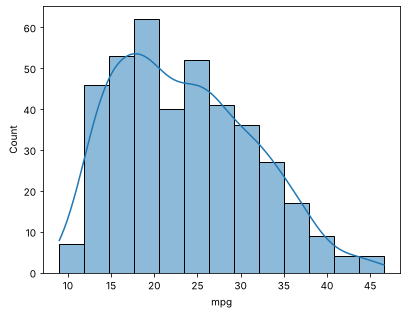

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.histplot(data=df, x='mpg', kde=True)
plt.show()

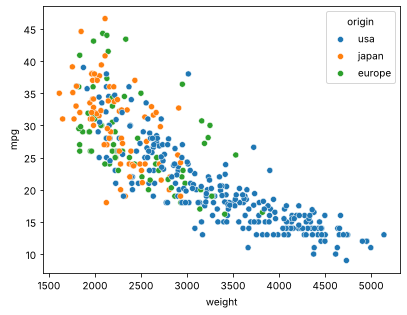

In [8]:
# 무게가 무거울수록 연비가 낮아져요 (음의 상관관계)
sns.scatterplot(data=df, x='weight', y='mpg', hue='origin')
plt.show()

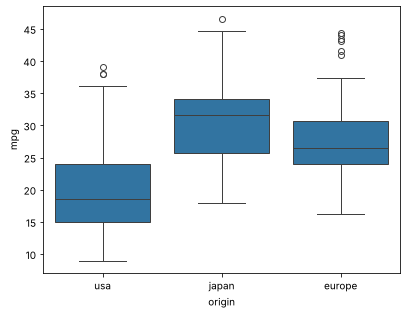

In [9]:
sns.boxplot(data=df, x='origin', y='mpg')
plt.show()

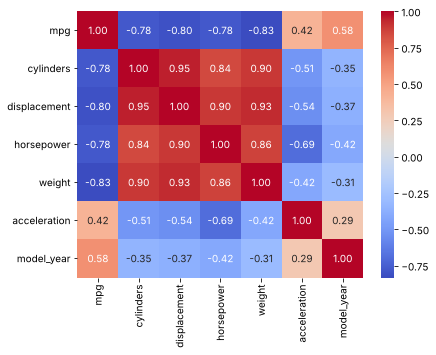

In [10]:
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt='.2f')
plt.show()

## 4. 전처리
### 4-1. 필요 없는 열 빼기, 결측치 채우기
`name`(차 이름)은 차마다 달라서 예측에 도움이 안 되니 빼요. 마력 빈칸 6개는 **평균값으로 채워** 볼게요.

In [11]:
df2 = df.drop(columns='name')
df2['horsepower'] = df2['horsepower'].fillna(df2['horsepower'].mean())
df2.isnull().sum()

mpg             0
cylinders       0
displacement    0
horsepower      0
weight          0
acceleration    0
model_year      0
origin          0
dtype: int64

### 4-2. 입력(X)과 정답(y) 나누기, 원-핫 인코딩

In [12]:
X = pd.get_dummies(df2.drop(columns='mpg'), columns=['origin'], dtype=int)
y = df2['mpg']
X.head()

,cylinders,displacement,horsepower,weight,acceleration,model_year,origin_europe,origin_japan,origin_usa
0,8,307,130,3504,12,70,0,0,1
1,8,350,165,3693,11.5,70,0,0,1
2,8,318,150,3436,11,70,0,0,1
3,8,304,150,3433,12,70,0,0,1
4,8,302,140,3449,10.5,70,0,0,1


### 4-3. 훈련/테스트 나누기와 정규화

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

scaler = MinMaxScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)
print('훈련:', X_train.shape, ' 테스트:', X_test.shape)

훈련: (318, 9)  테스트: (80, 9)


## 5. 모델 학습과 평가
회귀는 **오차**로 평가해요.
- **MAE (평균 절대 오차)**: 실제 값과 예측 값 차이의 평균. 작을수록 좋아요.
- **MSE (평균 제곱 오차)**: 차이를 제곱해서 평균. 크게 틀린 것에 벌점을 더 많이 줘요.

In [14]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

lin = LinearRegression()
lin.fit(X_train, y_train)
pred = lin.predict(X_test)
print('MAE:', round(mean_absolute_error(y_test, pred), 2), 'mpg')
print('MSE:', round(mean_squared_error(y_test, pred), 2))

MAE: 2.7 mpg
MSE: 10.99


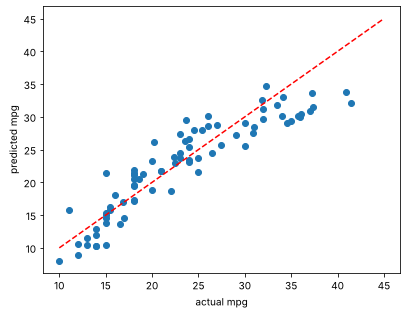

In [15]:
# 실제 값과 예측 값 비교: 빨간 선에 가까울수록 잘 맞힌 것
plt.scatter(y_test, pred)
plt.plot([10, 45], [10, 45], 'r--')
plt.xlabel('actual mpg'); plt.ylabel('predicted mpg')
plt.show()

In [16]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

knn = KNeighborsRegressor(n_neighbors=5).fit(X_train_s, y_train)
tree = DecisionTreeRegressor(max_depth=4, random_state=0).fit(X_train, y_train)
forest = RandomForestRegressor(n_estimators=100, random_state=0).fit(X_train, y_train)

pd.DataFrame({
    '모델': ['선형 회귀', 'KNN (K=5)', '의사결정트리 (깊이 4)', '랜덤 포레스트'],
    'MAE': [mean_absolute_error(y_test, lin.predict(X_test)),
            mean_absolute_error(y_test, knn.predict(X_test_s)),
            mean_absolute_error(y_test, tree.predict(X_test)),
            mean_absolute_error(y_test, forest.predict(X_test))]}).round(2)

,모델,MAE
0,선형 회귀,2.7
1,KNN (K=5),1.94
2,의사결정트리 (깊이 4),2.36
3,랜덤 포레스트,1.84


In [17]:
# 선형 회귀가 찾은 기울기(계수): 무게(weight)는 음수 → 무거울수록 연비가 떨어진다고 학습했어요
pd.Series(lin.coef_, index=X.columns).round(4)

cylinders       -0.4025
displacement     0.0252
horsepower      -0.0209
weight          -0.0067
acceleration     0.1911
model_year       0.7654
origin_europe    0.7240
origin_japan     1.2012
origin_usa      -1.9252
dtype: float64

## 6. 의사결정트리 깊이 바꿔 보기

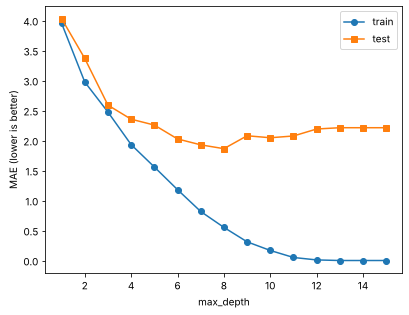

In [18]:
depths = range(1, 16)
train_mae, test_mae = [], []
for d in depths:
    m = DecisionTreeRegressor(max_depth=d, random_state=0).fit(X_train, y_train)
    train_mae.append(mean_absolute_error(y_train, m.predict(X_train)))
    test_mae.append(mean_absolute_error(y_test, m.predict(X_test)))

plt.plot(depths, train_mae, 'o-', label='train')
plt.plot(depths, test_mae, 's-', label='test')
plt.xlabel('max_depth'); plt.ylabel('MAE (lower is better)'); plt.legend()
plt.show()

## 7. 새 자동차 연비 예측하기
숫자를 바꿔서 다시 실행해 보세요.

In [19]:
new = pd.DataFrame([{'cylinders': 4, 'displacement': 120, 'horsepower': 90,
                     'weight': 2500, 'acceleration': 16, 'model_year': 80, 'origin': 'japan'}])

new_X = pd.get_dummies(new, columns=['origin'], dtype=int).reindex(columns=X.columns, fill_value=0)
mpg = forest.predict(new_X)[0]
print('랜덤 포레스트 예측:', round(mpg, 1), 'mpg  ≈', round(mpg * 0.425, 1), 'km/L')

랜덤 포레스트 예측: 32.2 mpg  ≈ 13.7 km/L


## 🚀 도전: 분류로 생산지 맞히기
이번에는 정답이 **범주(usa, europe, japan)**예요. 분류 문제가 되니 정확도로 평가해요.

정확도: 0.812
기준선(전부 usa라고 답할 때): 0.625


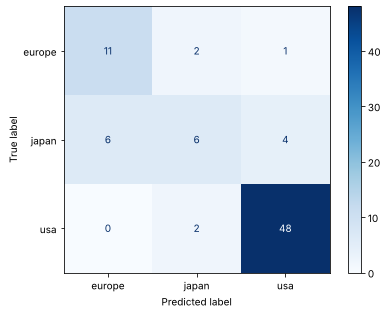

In [20]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import ConfusionMatrixDisplay

Xc = df2.drop(columns='origin')
yc = df2['origin']
Xc_train, Xc_test, yc_train, yc_test = train_test_split(Xc, yc, test_size=0.2, random_state=0, stratify=yc)

clf = RandomForestClassifier(n_estimators=100, random_state=0).fit(Xc_train, yc_train)
print('정확도:', round(clf.score(Xc_test, yc_test), 3))
print('기준선(전부 usa라고 답할 때):', round((yc_test == 'usa').mean(), 3))
ConfusionMatrixDisplay.from_estimator(clf, Xc_test, yc_test, cmap='Blues')
plt.show()